# Data Preparation and Cleaning
This notebook implements step-by-step data preparation: handling missing values, extracting datetime features, capping outliers, and encoding categorical variables.
Each code cell includes beginner-friendly comments explaining what the block does and why.

Checklist:
- Handle missing values (median for numeric, mode for categorical, drop very sparse columns)
- Convert datetime fields into engineered features (hour, day, month, season, weekend flag)
- Cap extreme outliers (IQR-based clipping for duration/distance-like columns)
- Encode categorical variables (one-hot encoding with get_dummies)

In [1]:
# Imports and data loading
# notes:
# - Import fundamental libraries (pandas, numpy).
# - Load your dataset from the project path. If the file is missing, raise a helpful error.
# - After loading we show the shape and first few rows so you can confirm it loaded correctly.
from pathlib import Path
import pandas as pd
import numpy as np
import warnings
# set display columns to max so that we can view all columns
pd.set_option('display.max_columns', None)
warnings.filterwarnings("ignore")

# Optional: nicer display for pandas in notebooks
pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 200)

# Update this path if your CSV is in a different location within the project
csv_path = Path("data/raw/US_Accidents_March23_NY.csv")

if not csv_path.exists():
    raise FileNotFoundError(f"CSV not found at {csv_path}. Please place the file there or change the path in this cell.")

# Read CSV (use low_memory=False to avoid dtype warnings for large CSVs)
df = pd.read_csv(csv_path, low_memory=False)
print("Loaded:", csv_path, "-> shape:", df.shape)

# Show the first 5 rows so you can inspect column names and sample values
df.head()

Loaded: data\raw\US_Accidents_March23_NY.csv -> shape: (347960, 46)


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-194257,Source2,3,2016-11-30 16:25:41,2016-11-30 17:10:30,41.139324,-74.169876,NaN,NaN,0.01,Right lane blocked due to accident on I-87 Sou...,Route 17,Sloatsburg,Rockland,NY,10974,US,US/Eastern,KCDW,2016-11-30 16:53:00,53.1,NaN,93.0,29.81,1.0,East,11.5,0.00,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
1,A-194258,Source2,3,2016-11-30 15:40:06,2016-11-30 17:09:40,41.118748,-74.159744,NaN,NaN,2.53,Accident on I-87 Southbound between Exit 14B C...,I-287 S,Suffern,Rockland,NY,10901,US,US/Eastern,KCDW,2016-11-30 15:53:00,53.1,NaN,93.0,29.83,1.0,ENE,8.1,0.02,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-194259,Source2,3,2016-11-30 15:26:18,2016-11-30 16:56:02,41.014034,-73.717239,NaN,NaN,1.17,Accident on I-287 Cross Westchester Expy Eastb...,Hutchinson River Pkwy S,White Plains,Westchester,NY,10605,US,US/Eastern,KHPN,2016-11-30 15:56:00,52.0,NaN,93.0,29.81,2.0,East,17.3,0.15,Light Rain,False,False,False,False,True,False,False,False,False,False,False,False,False,Day,Day,Day,Day
3,A-194260,Source2,3,2016-11-30 16:14:11,2016-11-30 16:59:00,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-194261,Source2,3,2016-11-30 16:17:57,2016-11-30 17:02:44,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day


In [2]:
# Quick inspection: missing values and a brief overview
# note: these commands help you learn which columns have the most missing values and the dataframe shape.
print("Shape:", df.shape)

# Top columns by missing count
missing = df.isnull().sum().sort_values(ascending=False)
print("Top missing columns:\n", missing.head(20))

# Show dtypes for reference
print("\nDtypes sample:\n", df.dtypes.head(20))

# Show a small sample of rows for eyeballing
df.sample(5, random_state=1)

Shape: (347960, 46)
Top missing columns:
 End_Lat                  153058
End_Lng                  153058
Precipitation(in)         86511
Wind_Chill(F)             71654
Wind_Speed(mph)           17879
Wind_Direction             4477
Visibility(mi)             3081
Pressure(in)               2984
Weather_Condition          2726
Humidity(%)                2191
Temperature(F)             2068
Weather_Timestamp          1459
Nautical_Twilight           710
Civil_Twilight              710
Sunrise_Sunset              710
Astronomical_Twilight       710
Street                      648
Airport_Code                347
City                         28
Description                   1
dtype: int64

Dtypes sample:
 ID                    object
Source                object
Severity               int64
Start_Time            object
End_Time              object
Start_Lat            float64
Start_Lng            float64
End_Lat              float64
End_Lng              float64
Distance(mi)         float6

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
61010,A-1463392,Source2,2,2020-05-08 05:31:37,2020-05-08 06:18:43,40.683205,-73.688599,NaN,NaN,0.000,Accident on Southern Pkwy Southbound at Corona...,Southern State Pkwy W,Valley Stream,Nassau,NY,11580,US,US/Eastern,KJFK,2020-05-08 05:51:00,49.0,45.0,33.0,29.85,10.0,NW,10.0,0.0,Mostly Cloudy,False,False,False,False,True,False,False,False,False,False,False,False,False,Night,Day,Day,Day
278018,A-5896303,Source1,2,2021-05-25 12:02:00,2021-05-25 13:23:16,43.274378,-75.190950,43.274933,-75.191263,0.041,Incident on MAPPA AVE near BOON ST Expect long...,Boone St,Barneveld,Oneida,NY,13304-2401,US,US/Eastern,KRME,2021-05-25 11:53:00,73.0,73.0,61.0,29.56,10.0,VAR,5.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
243379,A-5102399,Source1,2,2022-07-09 15:36:54,2022-07-09 17:18:05,40.922173,-73.818415,40.936723,-73.807235,1.162,Incident on CROSS COUNTY PKWY near CROSS COUNT...,Cross County Pkwy,Mt Vernon,Westchester,NY,10552,US,US/Eastern,KLGA,2022-07-09 15:51:00,83.0,83.0,39.0,29.98,10.0,SSE,9.0,0.0,Mostly Cloudy,False,False,False,False,True,False,False,False,False,False,False,False,False,NaN,NaN,NaN,NaN
280219,A-5961289,Source1,2,2021-08-26 06:01:00.000000000,2021-08-26 07:57:55.000000000,42.205578,-73.636883,42.208088,-73.636823,0.173,Incident on TACONIC STATE PKWY NB near NY-23 R...,Taconic State Pkwy,Craryville,Columbia,NY,12521,US,US/Eastern,KPSF,2021-08-26 06:03:00,64.0,64.0,96.0,28.88,1.0,CALM,0.0,0.0,Fog,False,False,False,False,True,False,False,False,False,False,False,False,False,Night,Day,Day,Day
272221,A-5726709,Source1,2,2021-03-06 14:39:26.000000000,2021-03-06 16:50:34.000000000,40.666162,-73.792623,40.667412,-73.774693,0.944,Crash on Belt Parkway eastbound Rockaway Blvd ...,Belt Pkwy,Jamaica,Queens,NY,11436,US,US/Eastern,KJFK,2021-03-06 14:51:00,34.0,22.0,37.0,30.07,10.0,NW,21.0,0.0,Mostly Cloudy / Windy,False,False,False,True,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     347960 non-null  object 
 1   Source                 347960 non-null  object 
 2   Severity               347960 non-null  int64  
 3   Start_Time             347960 non-null  object 
 4   End_Time               347960 non-null  object 
 5   Start_Lat              347960 non-null  float64
 6   Start_Lng              347960 non-null  float64
 7   End_Lat                194902 non-null  float64
 8   End_Lng                194902 non-null  float64
 9   Distance(mi)           347960 non-null  float64
 10  Description            347959 non-null  object 
 11  Street                 347312 non-null  object 
 12  City                   347932 non-null  object 
 13  County                 347960 non-null  object 
 14  State                  347960 non-nu

In [4]:
# 1) Handle missing values
# Notes:
# - create a copy of the data to avoid accidental modification of the original.
# - convert datetime columns 
# - drop columns that are mostly empty (threshold adjustable).


# working copy
df_clean = df.copy()

# Drop rows missing core info: coordinates or start time or severity
df_clean = df_clean.dropna(subset=['Start_Time', 'Start_Lat', 'Start_Lng', 'Severity'])
df_clean['Severity'] = df_clean['Severity'].astype(int)

# Convert common datetime columns 
for dt_col in ['Start_Time', 'End_Time']:
    if dt_col in df_clean.columns:
        df_clean[dt_col] = pd.to_datetime(df_clean[dt_col], errors='coerce')
        print(f"Converted {dt_col} to datetime (sample non-null count = {df_clean[dt_col].notna().sum()})")

# 1) Drop very sparse columns (adjust threshold as needed)
sparse_thresh = 0.4  # drop columns with more than 40% missing values
missing_frac = df_clean.isna().mean()
cols_to_drop = missing_frac[missing_frac > sparse_thresh].index.tolist()
if cols_to_drop:
    print("Dropping columns with >40% missing values:", cols_to_drop)
    df_clean.drop(columns=cols_to_drop, inplace=True)




Converted Start_Time to datetime (sample non-null count = 310351)
Converted End_Time to datetime (sample non-null count = 310351)
Dropping columns with >40% missing values: ['End_Lat', 'End_Lng']


In [5]:
# Keep essential columns (avoid loading unnecessary columns for now)
keep = [
    'ID', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng',
    'Distance(mi)', 'Description', 'Street', 'City', 'County', 'State',
    'Timezone', 'Weather_Timestamp','Temperature(F)','Wind_Chill(F)', 'Visibility(mi)', 'Pressure(in)','Humidity(%)',
    'Weather_Condition','Wind_Direction','Wind_Speed(mph)',
    'Amenity','Bump','Crossing','Give_Way','Junction','No_Exit','Railway',
    'Roundabout','Station','Stop','Traffic_Calming','Traffic_Signal','Turning_Loop'
]
# keep only columns that exist in dataframe

df_clean = df_clean[keep].copy()

In [6]:
len(df_clean.columns)

35

In [7]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 35 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   ID                 347960 non-null  object        
 1   Severity           347960 non-null  int32         
 2   Start_Time         310351 non-null  datetime64[ns]
 3   End_Time           310351 non-null  datetime64[ns]
 4   Start_Lat          347960 non-null  float64       
 5   Start_Lng          347960 non-null  float64       
 6   Distance(mi)       347960 non-null  float64       
 7   Description        347959 non-null  object        
 8   Street             347312 non-null  object        
 9   City               347932 non-null  object        
 10  County             347960 non-null  object        
 11  State              347960 non-null  object        
 12  Timezone           347960 non-null  object        
 13  Weather_Timestamp  346501 non-null  object  

In [8]:
numeric_cols = df_clean.select_dtypes(include='number').columns.tolist()
numeric_cols

['Severity',
 'Start_Lat',
 'Start_Lng',
 'Distance(mi)',
 'Temperature(F)',
 'Wind_Chill(F)',
 'Visibility(mi)',
 'Pressure(in)',
 'Humidity(%)',
 'Wind_Speed(mph)']

In [9]:
# Drop rows with unexpected severity values
df_clean = df_clean[df_clean['Severity'].notna()]

In [10]:
# Note: dropping rows can introduce bias if missingness is systematic — logging the count and investigated missingness before proceeding.
# Keep only rows with Start_Time because subsequent time-based feature engineering (hour, weekday, Month etc) requires it.
print("dropping rows",len(df_clean[df_clean['Start_Time'].isna()]))

dropping rows 37609


In [11]:
df_clean[df_clean['Start_Time'].notna()].head(5)

,ID,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),Description,Street,City,County,State,Timezone,Weather_Timestamp,Temperature(F),Wind_Chill(F),Visibility(mi),Pressure(in),Humidity(%),Weather_Condition,Wind_Direction,Wind_Speed(mph),Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop
0,A-194257,3,2016-11-30 16:25:41,2016-11-30 17:10:30,41.139324,-74.169876,0.01,Right lane blocked due to accident on I-87 Sou...,Route 17,Sloatsburg,Rockland,NY,US/Eastern,2016-11-30 16:53:00,53.1,NaN,1.0,29.81,93.0,Overcast,East,11.5,False,False,False,False,False,False,False,False,False,False,False,False,False
1,A-194258,3,2016-11-30 15:40:06,2016-11-30 17:09:40,41.118748,-74.159744,2.53,Accident on I-87 Southbound between Exit 14B C...,I-287 S,Suffern,Rockland,NY,US/Eastern,2016-11-30 15:53:00,53.1,NaN,1.0,29.83,93.0,Overcast,ENE,8.1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,A-194259,3,2016-11-30 15:26:18,2016-11-30 16:56:02,41.014034,-73.717239,1.17,Accident on I-287 Cross Westchester Expy Eastb...,Hutchinson River Pkwy S,White Plains,Westchester,NY,US/Eastern,2016-11-30 15:56:00,52.0,NaN,2.0,29.81,93.0,Light Rain,East,17.3,False,False,False,False,True,False,False,False,False,False,False,False,False
3,A-194260,3,2016-11-30 16:14:11,2016-11-30 16:59:00,41.390369,-73.597969,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,US/Eastern,2016-11-30 15:53:00,52.0,NaN,3.0,29.86,89.0,Rain,East,10.4,False,False,False,False,False,False,False,False,False,False,False,False,False
4,A-194261,3,2016-11-30 16:17:57,2016-11-30 17:02:44,41.390369,-73.597969,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,US/Eastern,2016-11-30 15:53:00,52.0,NaN,3.0,29.86,89.0,Rain,East,10.4,False,False,False,False,False,False,False,False,False,False,False,False,False


In [12]:
# Keep only rows with Start_Time because subsequent time-based feature engineering (hour, weekday, Month etc) requires it.
df_clean = df_clean[df_clean['Start_Time'].notna()]

In [13]:
df_clean.shape

(310351, 35)

In [14]:
# Drop rows with missing Weather_Condition because they are few and we'd rather avoid risky imputations
# Log how many rows we remove
len(df_clean[df_clean['Weather_Condition'].isna()]) 

2533

In [15]:
# Drop rows with missing Weather_Condition because they are few and we'd rather avoid risky imputations
df_clean = df_clean[df_clean['Weather_Condition'].notna()]

In [16]:
df_clean.shape

(307818, 35)

In [17]:
df.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description', 'Street', 'City', 'County', 'State', 'Zipcode', 'Country',
       'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)',
       'Weather_Condition', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop',
       'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight'],
      dtype='object')

### Feature Engineering

In [18]:

# Simple temporal features
df_clean['Hour'] = df_clean['Start_Time'].dt.hour
df_clean['Weekday'] = df_clean['Start_Time'].dt.day_name()
df_clean['Month'] = df_clean['Start_Time'].dt.month_name()
df_clean['Day'] = df_clean['Start_Time'].dt.day
df_clean['Day_of_week'] = df_clean['Start_Time'].dt.dayofweek  # 0=Mon
df_clean['Is_weekend'] = df_clean['Day_of_week'].isin([5,6]).astype(int)

# Duration in minutes 

df_clean['Duration_min'] = (pd.to_datetime(df_clean['End_Time']) - pd.to_datetime(df_clean['Start_Time'])).dt.total_seconds() / 60.0
# Replace negative or extremely large durations with NaN
df_clean.loc[(df_clean['Duration_min'] < 0) | (df_clean['Duration_min'] > 60*24), 'Duration_min'] = np.nan



# Simplify weather into coarse categories 

#  Prepare cleaned column (handles NaN)
df_clean['Weather_raw'] = df_clean['Weather_Condition'].fillna('missing').astype(str).str.lower().str.strip()

# Simple mapping function (readable and easy to adjust)
def map_weather_simple(txt):
    if txt is None:
        return 'Missing'
    t = txt.lower()
    if t.strip() in ['', 'nan', 'missing', 'n/a', 'n/a precipitation']:
        return np.nan
    # Severe / thunder-related
    if any(k in t for k in ['thunder', 't-storm', 'tstorm', 't-storm', 'tornado', 'heavy t-storm', 'thunderstorm']):
        return 'Thunder/Severe'
    # Snow or freezing / ice
    if any(k in t for k in ['snow', 'sleet', 'freez', 'ice', 'wintry', 'blizzard', 'pellets']):
        return 'Snow/Ice'
    # Rain and drizzle
    if any(k in t for k in ['rain', 'drizzle', 'showers', 'downpour', 'shower']):
        return 'Rain/Precip'
    # Fog, mist, haze, smoke => low visibility
    if any(k in t for k in ['fog', 'mist', 'haze', 'smoke', 'low visibility', 'shallow fog', 'patches of fog']):
        return 'LowVisibility'
    # Wind-related
    if any(k in t for k in ['wind', 'windy', 'squall', 'gust']):
        return 'Windy'
    # Clear / cloudy / fair
    if any(k in t for k in ['clear', 'sunny', 'fair', 'cloudy', 'overcast', 'partly cloudy', 'mostly cloudy', 'scattered','hail']):
        return 'Cloudy/Clear'
    # Fallback
    return 'Other'

#  Apply mapping (vectorized via .apply; fast enough for typical datasets)
df_clean['Weather_Short'] = df_clean['Weather_raw'].apply(map_weather_simple)

# Quick sanity check (optional)
print(df_clean['Weather_Short'].value_counts(dropna=False))

# Season mapping (Northern Hemisphere)
def month_to_season(m):
    if pd.isna(m):
        return 'Missing'
    m = int(m)
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

df_clean['Season'] = df_clean['Start_Time'].dt.month.apply(month_to_season)


# Consolidate severity into 3 classes (Minor / Moderate / Major)
# Mapping: 1-> Minor, 2 -> Moderate 3 and 4 -> Major 
df_clean['Severity_Class'] = df_clean['Severity'].map({1:'Minor', 2:'Moderate', 3:'Major', 4:'Major'})


# Quick sanity checks and simple diagnostics
print("Severity class counts:\n",df_clean['Severity_Class'].value_counts())
print("Sample of weather categories:", df_clean['Weather_Short'].value_counts().to_dict())
print("Sample of Seasons:", df_clean['Season'].value_counts().to_dict())

Weather_Short
Cloudy/Clear      249984
Rain/Precip        27094
Snow/Ice           18483
Windy               5301
LowVisibility       5109
Thunder/Severe      1769
NaN                   78
Name: count, dtype: int64
Severity class counts:
 Severity_Class
Moderate    227266
Major        79311
Minor         1241
Name: count, dtype: int64
Sample of weather categories: {'Cloudy/Clear': 249984, 'Rain/Precip': 27094, 'Snow/Ice': 18483, 'Windy': 5301, 'LowVisibility': 5109, 'Thunder/Severe': 1769}
Sample of Seasons: {'Autumn': 85338, 'Winter': 78047, 'Summer': 76948, 'Spring': 67485}


In [19]:
len(df_clean[df_clean['Weather_Short'].isna()]) 

78

In [20]:
# Keep rows with Weather_Short because downstream weather-based features require a valid category;
# drop the rows and the count is small.
df_clean = df_clean[df_clean['Weather_Short'].notna()]

In [21]:
df_clean['Weather_Short'].unique()

array(['Cloudy/Clear', 'Rain/Precip', 'LowVisibility', 'Snow/Ice',
       'Thunder/Severe', 'Windy'], dtype=object)

In [22]:
df_clean.shape

(307740, 46)

In [23]:
df_clean['Season'].isna().sum()

0

In [24]:
df_clean.columns

Index(['ID', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'Distance(mi)', 'Description', 'Street', 'City', 'County', 'State', 'Timezone', 'Weather_Timestamp', 'Temperature(F)',
       'Wind_Chill(F)', 'Visibility(mi)', 'Pressure(in)', 'Humidity(%)', 'Weather_Condition', 'Wind_Direction', 'Wind_Speed(mph)', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit',
       'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop', 'Hour', 'Weekday', 'Month', 'Day', 'Day_of_week', 'Is_weekend', 'Duration_min', 'Weather_raw',
       'Weather_Short', 'Season', 'Severity_Class'],
      dtype='object')

In [25]:
# Clean infrastructure binary flags to 0/1

drop_cols = ["ID","Timezone","Description","Weather_raw"]
infra_cols = [
    'Amenity','Bump','Crossing','Give_Way','Junction','No_Exit','Railway',
    'Roundabout','Station','Stop','Traffic_Calming','Traffic_Signal','Turning_Loop'
] 

numeric_cols = ['Distance(mi)','Temperature(F)','Wind_Chill(F)','Visibility(mi)',
                        'Humidity(%)','Pressure(in)','Wind_Speed(mph)','Hour','Duration_min']

category_cols = ["Street","City", "County","Weather_Condition","Wind_Direction","Weather_Short","Season"]

#list of sentinel values used in your dataset that should be treated as missing
SENTINELS = [-999, -9999, 9999, 99999, 'NA', 'N/A', 'None', 'none', 'nan']

# Replace sentinel numeric values with np.nan so median imputation handles them
df_clean = df_clean.replace(SENTINELS, np.nan)


for c in infra_cols:
    # Map common truthy/falsy values to 1/0; fill missing with 0
    df_clean[c] = df_clean[c].replace({True:1, False:0, 'True':1, 'False':0, 'true':1, 'false':0}).fillna(0).astype(int)

# Handle missing numeric values with simple imputation (median)

for c in numeric_cols:
    median = float(df_clean[c].median())
    df_clean[c] = df_clean[c].fillna(median)


# Drop rows with unexpected severity values
df_clean = df_clean[df_clean['Severity_Class'].notna()]

             column datatype  outlier_count  outlier_pct
0         Start_Lng  float64          77376    25.143303
1    Visibility(mi)  float64          66019    21.452850
2        Is_weekend    int32          50504    16.411256
3    Traffic_Signal    int32          46386    15.073114
4          Crossing    int32          41212    13.391824
5      Distance(mi)  float64          37663    12.238578
6          Junction    int32          37398    12.152466
7      Duration_min  float64          30938    10.053292
8              Stop    int32          10039     3.262169
9           Amenity    int32           9175     2.981413
10  Wind_Speed(mph)  float64           8208     2.667187
11          Station    int32           6964     2.262949
12     Pressure(in)  float64           6356     2.065380
13         Give_Way    int32           3136     1.019042
14          Railway    int32           2927     0.951128
15    Wind_Chill(F)  float64            986     0.320400
16          No_Exit    int32   

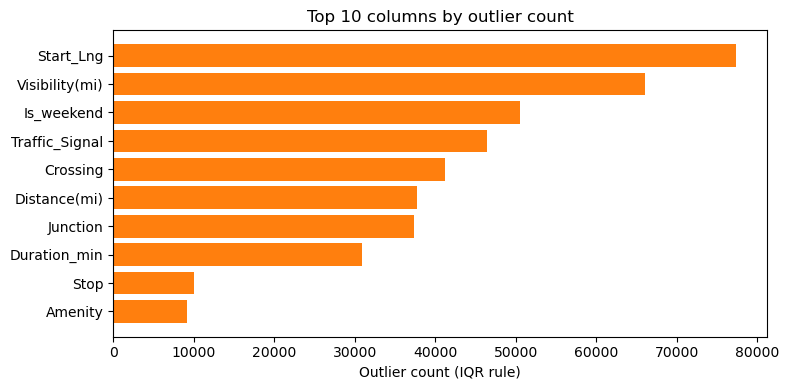

In [26]:
import matplotlib.pyplot as plt
def outlier_summary_iqr(df, exclude_cols=None, iqr_factor=1.5, min_count_for_plot=5):
    """
    Returns a DataFrame with outlier counts and percentages per numeric column.
    exclude_cols: list of column names to skip (e.g., target, ID, lat/lng)
    iqr_factor: multiplier for IQR (1.5 is standard)
    """
    if exclude_cols is None:
        exclude_cols = []

    # 1) select numeric columns and remove excludes
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    numeric_cols = [c for c in numeric_cols if c not in exclude_cols]

    rows = []
    n_rows = len(df)

    for c in numeric_cols:
        col = df[c].dropna()
        if col.empty:
            rows.append((c, 0, 0.0))
            continue
        q1 = col.quantile(0.25)
        q3 = col.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - iqr_factor * iqr
        upper = q3 + iqr_factor * iqr
        # boolean mask of outliers (including values exactly outside bounds)
        out_mask = (df[c] < lower) | (df[c] > upper)
        out_count = int(out_mask.sum())
        out_pct = out_count / n_rows * 100.0
        rows.append((c,col.dtype, out_count, out_pct))

    summary = pd.DataFrame(rows, columns=['column','datatype', 'outlier_count', 'outlier_pct'])
    summary = summary.sort_values(by='outlier_count', ascending=False).reset_index(drop=True)
    return summary

# Optional small plotting helper
def plot_top_outliers(summary_df, top_k=10):
    top = summary_df.head(top_k)
    plt.figure(figsize=(8, max(3, 0.4 * len(top))))
    plt.barh(top['column'][::-1], top['outlier_count'][::-1], color='C1')
    plt.xlabel('Outlier count (IQR rule)')
    plt.title(f'Top {len(top)} columns by outlier count')
    plt.tight_layout()
    plt.show()

  
# exclude ID-like or coordinate columns if you don't want them considered
exclude = ["ID","Timezone"]  # adapt to your df_clean
summary = outlier_summary_iqr(df_clean, exclude_cols=exclude, iqr_factor=1.5)

# show results
print(summary)

# plot the top 5 columns with most outliers
plot_top_outliers(summary, top_k=10)

In [27]:
# checking y its variance is 0
# 1. type and nulls
print(df_clean['Visibility(mi)'].dtype, "non-null:", df_clean['Visibility(mi)'].notna().sum())

# 2. unique values and variance
print("unique:", df_clean['Visibility(mi)'].nunique(dropna=False))
print("min/max:", df_clean['Visibility(mi)'].min(), df_clean['Visibility(mi)'].max())
print("var:", df_clean['Visibility(mi)'].astype(float).var(ddof=0))

float64 non-null: 307740
unique: 32
min/max: 0.0 105.0
var: 8.002692786789401


In [28]:
# Cap extreme outliers using the IQR method (1.5 * IQR)
# Note: outliers can skew models. We compute lower/upper fences per column and clip values.

# Candidate numeric columns to cap 


print("Numeric columns considered for outlier capping:", numeric_cols)

for col in numeric_cols:
    series = df_clean[col].dropna()
    if series.empty:
        continue
    if col == "Visibility(mi)": # it caps as a single value need to handle seperately becaue it lose variance and higly skewed 
        lower = df_clean['Visibility(mi)'].quantile(0.01)
        upper = df_clean['Visibility(mi)'].quantile(0.99)
    else:
    
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        lower = float(Q1 - 1.5 * IQR)
        upper = float(Q3 + 1.5 * IQR)

    
    # Clip values to the fences — this keeps outliers but reduces their effect
    print(col)
    before_extremes = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    df_clean[col] = df_clean[col].clip(lower=lower, upper=upper)
    after_extremes = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f"Capped outliers in '{col}': before={before_extremes}, after={after_extremes} (lower={lower}, upper={upper})")

df_clean[numeric_cols].describe() if numeric_cols else print('No numeric columns to describe')

Numeric columns considered for outlier capping: ['Distance(mi)', 'Temperature(F)', 'Wind_Chill(F)', 'Visibility(mi)', 'Humidity(%)', 'Pressure(in)', 'Wind_Speed(mph)', 'Hour', 'Duration_min']
Distance(mi)
Capped outliers in 'Distance(mi)': before=37663, after=0 (lower=-0.8955, upper=1.4925)
Temperature(F)
Capped outliers in 'Temperature(F)': before=37, after=0 (lower=-9.0, upper=119.0)
Wind_Chill(F)
Capped outliers in 'Wind_Chill(F)': before=986, after=0 (lower=-8.750000000000007, upper=107.65)
Visibility(mi)
Capped outliers in 'Visibility(mi)': before=4031, after=0 (lower=0.5, upper=15.0)
Humidity(%)
Capped outliers in 'Humidity(%)': before=0, after=0 (lower=-1.0, upper=135.0)
Pressure(in)
Capped outliers in 'Pressure(in)': before=6356, after=0 (lower=28.905, upper=30.784999999999997)
Wind_Speed(mph)
Capped outliers in 'Wind_Speed(mph)': before=8208, after=0 (lower=-3.500000000000001, upper=21.3)
Hour
Capped outliers in 'Hour': before=0, after=0 (lower=-4.0, upper=28.0)
Duration_min
C

,Distance(mi),Temperature(F),Wind_Chill(F),Visibility(mi),Humidity(%),Pressure(in),Wind_Speed(mph),Hour,Duration_min
count,307740.000000,307740.000000,307740.000000,307740.000000,307740.000000,307740.000000,307740.000000,307740.000000,307740.000000
mean,0.364784,54.525107,49.209403,8.954172,66.154871,29.831316,8.902568,12.009593,95.518317
std,0.533643,19.248921,20.154787,2.751733,20.135461,0.355419,5.078767,5.518963,77.280419
min,0.000000,-9.000000,-8.750000,0.500000,1.000000,28.905000,0.000000,0.000000,1.916667
25%,0.000000,39.000000,34.900000,10.000000,50.000000,29.610000,5.800000,8.000000,29.933333
50%,0.027000,55.000000,51.000000,10.000000,67.000000,29.880000,8.100000,12.000000,64.966667
75%,0.597000,71.000000,64.000000,10.000000,84.000000,30.080000,12.000000,16.000000,127.666667
max,1.492500,119.000000,107.650000,15.000000,100.000000,30.785000,21.300000,23.000000,274.266667


In [29]:
df_clean["Visibility(mi)"].isna().sum()

0

In [30]:
df_clean["Wind_Direction"].unique()

array(['East', 'ENE', 'South', 'SSE', 'NE', 'NNE', 'North', 'West', 'NW',
       'WNW', 'Variable', 'SW', 'WSW', 'ESE', 'NNW', 'Calm', 'SE', 'SSW',
       'N', 'VAR', 'CALM', 'E', 'S', 'W', nan], dtype=object)

In [31]:
# Clean Wind_Direction

# Step 1: normalize strings
wd = df_clean['Wind_Direction'].astype(str).str.strip().str.upper()
# Step 2: canonical mapping (full names, variants -> standard abbreviations or special tokens)
mapping = {
    # cardinal / intercardinal full names
    'NORTH': 'N', 'N': 'N',
    'NNE': 'NNE', 'NORTH-NORTHEAST': 'NNE',
    'NE': 'NE', 'NORTHEAST': 'NE',
    'ENE': 'ENE', 'EAST-NORTHEAST': 'ENE',
    'E': 'E', 'EAST': 'E',
    'ESE': 'ESE', 'EAST-SOUTHEAST': 'ESE',
    'SE': 'SE', 'SOUTHEAST': 'SE',
    'SSE': 'SSE', 'SOUTH-SOUTHEAST': 'SSE',
    'S': 'S', 'SOUTH': 'S',
    'SSW': 'SSW', 'SOUTH-SOUTHWEST': 'SSW',
    'SW': 'SW', 'SOUTHWEST': 'SW',
    'WSW': 'WSW', 'WEST-SOUTHWEST': 'WSW',
    'W': 'W', 'WEST': 'W',
    'WNW': 'WNW', 'WEST-NORTHWEST': 'WNW',
    'NW': 'NW', 'NORTHWEST': 'NW',
    'NNW': 'NNW', 'NORTH-NORTHWEST': 'NNW',

    # special / synonyms
    'VARIABLE': 'Variable', 'VAR': 'Variable',
    'CALM': 'Calm',
    'MISSING': np.nan, 'NONE': np.nan, 'NAN': np.nan, '': np.nan
}

# Step 3: map values and preserve NaNs
wd_mapped = wd.map(mapping).fillna(wd)  # keep unmapped tokens for inspection

# Assign back to dataframe
df_clean['Wind_Direction_clean'] = wd_mapped
# Quick diagnostics
print("Unique cleaned values:", df_clean['Wind_Direction_clean'].unique())
print("NaN values:", df_clean['Wind_Direction_clean'].isna().sum())

Unique cleaned values: ['E' 'ENE' 'S' 'SSE' 'NE' 'NNE' 'N' 'W' 'NW' 'WNW' 'Variable' 'SW' 'WSW'
 'ESE' 'NNW' 'Calm' 'SE' 'SSW' 'NAN']
NaN values: 0


In [32]:
# Encode categorical variables (one-hot encoding)
# Note: we convert object/categorical columns into numeric columns using get_dummies.
# We use drop_first=True to avoid redundant dummy columns (helps some linear models).


print("Categorical columns to encode:", category_cols)

# updated the City column with proper city of county 'Westchester' and street 'King St'
# verifying the Data 
# df_clean[(df_clean['City'].isna()) & (df_clean['County']=="Westchester") ]
# df_clean[(df_clean['City'].isna())]['County'].unique()
# df_clean[(df_clean['City'].isna())]['Street'].unique()

df_clean['City'] = df_clean['City'].fillna('Yonkers').astype(str)

# verifying the Data 
# df_clean[(df_clean['Street'] == 'King St') & (df_clean['County']=="Westchester")]['City'].unique()


# df_clean[df_clean['Street'].isna()][['City','County']].value_counts()

# df_clean[(df_clean['County'] == 'Kings') & ( df_clean['City'] == 'Brooklyn')][['Street']]

# # Step 1: Fill missing Street values per County and City
# df_clean['Street'] = df_clean.groupby(['County', 'City'])['Street'].transform(
#     lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Missing')
# )

# # Step 2: Frequency encode Street for modeling
# street_freq = df_clean['Street'].value_counts().to_dict()
# df_clean['Street_encoded'] = df_clean['Street'].map(street_freq)

# Benefit: This avoids bias from assuming missing values follow the majority pattern, 
# and it makes the pipeline more transparent and reproducible.

# Step 1: Replace missing Street values with "Missing"
df_clean['Street'] = df_clean['Street'].fillna('Missing')

# Step 2: Frequency encode Street for modeling
street_freq = df_clean['Street'].value_counts().to_dict()
df_clean['Street_encoded'] = df_clean['Street'].map(street_freq)

city_freq = df_clean['City'].value_counts().to_dict()
df_clean['City_encoded'] = df_clean['City'].map(city_freq)


# Optional: Check results
print("Missing Street values after imputation:", df_clean['Street'].isna().sum())
print("Example of encoded Street values:")
print(df_clean[['County', 'City', 'Street', 'Street_encoded']].head())


#To encode.
category_to_exclude = ["Street", "City"]

# Replace missing Wind_Direction values with "Missing"
df_clean['Wind_Direction'] = df_clean['Wind_Direction'].fillna('Missing')

filtered_category_cols = [item for item in category_cols if item not in category_to_exclude]

df_encoded = pd.get_dummies(df_clean, columns=filtered_category_cols, drop_first=True) 
print("Shape before encoding:", df_clean.shape)
print("Shape after encoding:", df_encoded.shape)



# -----------------------


Categorical columns to encode: ['Street', 'City', 'County', 'Weather_Condition', 'Wind_Direction', 'Weather_Short', 'Season']
Missing Street values after imputation: 0
Example of encoded Street values:
        County          City                   Street  Street_encoded
0     Rockland    Sloatsburg                 Route 17             118
1     Rockland       Suffern                  I-287 S             141
2  Westchester  White Plains  Hutchinson River Pkwy S            1682
3       Putnam      Brewster                   I-84 E            1895
4       Putnam      Brewster                   I-84 E            1895
Shape before encoding: (307740, 49)
Shape after encoding: (307740, 222)


In [33]:
df_clean.to_csv('data/clean/US_Accidents_March23_NY_Clean.csv', index=False)

In [34]:
df_clean.select_dtypes(include=[np.number]).columns.tolist()


['Severity',
 'Start_Lat',
 'Start_Lng',
 'Distance(mi)',
 'Temperature(F)',
 'Wind_Chill(F)',
 'Visibility(mi)',
 'Pressure(in)',
 'Humidity(%)',
 'Wind_Speed(mph)',
 'Amenity',
 'Bump',
 'Crossing',
 'Give_Way',
 'Junction',
 'No_Exit',
 'Railway',
 'Roundabout',
 'Station',
 'Stop',
 'Traffic_Calming',
 'Traffic_Signal',
 'Turning_Loop',
 'Hour',
 'Day',
 'Day_of_week',
 'Is_weekend',
 'Duration_min',
 'Street_encoded',
 'City_encoded']

In [35]:
# Compute correlation matrix
df_clean['Visibility(mi)'] = pd.to_numeric(df_clean['Visibility(mi)'], errors='coerce')
df_clean["Visibility(mi)"] = pd.to_numeric(df_clean["Visibility(mi)"])
corr_matrix = df_clean[numeric_cols].corr().abs()
corr_matrix
corr = df_clean[numeric_cols].corr().abs()
corr

,Distance(mi),Temperature(F),Wind_Chill(F),Visibility(mi),Humidity(%),Pressure(in),Wind_Speed(mph),Hour,Duration_min
Distance(mi),1.000000,0.037489,0.072802,0.015952,0.039401,0.060066,0.014209,0.028703,0.333095
Temperature(F),0.037489,1.000000,0.896260,0.235878,0.196926,0.035674,0.075834,0.157403,0.052139
Wind_Chill(F),0.072802,0.896260,1.000000,0.223494,0.158328,0.086929,0.155943,0.131399,0.063551
Visibility(mi),0.015952,0.235878,0.223494,1.000000,0.498241,0.162959,0.005568,0.082217,0.019471
Humidity(%),0.039401,0.196926,0.158328,0.498241,1.000000,0.205059,0.207966,0.258773,0.064845
Pressure(in),0.060066,0.035674,0.086929,0.162959,0.205059,1.000000,0.067327,0.026012,0.050822
Wind_Speed(mph),0.014209,0.075834,0.155943,0.005568,0.207966,0.067327,1.000000,0.090630,0.012408
Hour,0.028703,0.157403,0.131399,0.082217,0.258773,0.026012,0.090630,1.000000,0.030808
Duration_min,0.333095,0.052139,0.063551,0.019471,0.064845,0.050822,0.012408,0.030808,1.000000


In [36]:
from scipy import stats

# 1) Simple correlation filter for numeric columns
def corr_filter_simple(df, numeric_cols=None, threshold=0.9):
    """
    Drop one column from highly correlated pairs.
    - df: DataFrame
     - threshold: abs(correlation) above which to consider redundancy
    Returns: keep_cols (list), drop_cols (list)
    """


    corr = df[numeric_cols].corr().abs()
    np.fill_diagonal(corr.values, 0.0)

    to_drop = set()
    cols = corr.columns.tolist()
    for i in range(len(cols)):
        if cols[i] in to_drop:
            continue
        for j in range(i+1, len(cols)):
            if cols[j] in to_drop:
                continue
            if corr.iloc[i, j] >= threshold:
                # drop the column with higher mean correlation to others
                mean_i = corr.loc[cols[i]].mean()
                mean_j = corr.loc[cols[j]].mean()
                drop = cols[i] if mean_i >= mean_j else cols[j]
                to_drop.add(drop)

    keep = [c for c in numeric_cols if c not in to_drop]
    return keep, sorted(to_drop)

# 2) Simple chi-square test for categorical features vs categorical target
def chi2_select_simple(df, cat_cols, target_col, alpha=0.05, min_expected=5):
    """
    Run chi-square test for each categorical column against a categorical target.
    - df: DataFrame
    - cat_cols: list of categorical columns to test
    - target_col: categorical target column name
    - alpha: significance threshold (default 0.05)
    Returns: results_df with columns ['chi2','p_value','dof','significant','note']
    """
    print(cat_cols)
    results = []
    for col in cat_cols:
        if col not in df.columns:
            results.append((col, np.nan, np.nan, np.nan, False, 'missing_column'))
            continue
        table = pd.crosstab(df[col].fillna('MISSING'), df[target_col].fillna('MISSING'))
        try:
            chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
            note = 'small_expected' if (expected < min_expected).any() else ''
            significant = p <= alpha
            results.append((col, float(chi2), float(p), int(dof), bool(significant), note))
        except Exception as e:
            results.append((col, np.nan, np.nan, np.nan, False, f'error:{e}'))

    res_df = pd.DataFrame(results, columns=['feature','chi2','p_value','dof','significant','note']).set_index('feature')
    return res_df



# numeric correlation filtering
keep_num, drop_num = corr_filter_simple(df_clean, numeric_cols=numeric_cols, threshold=0.8)
print("Keep numeric:", keep_num)
print("Drop numeric:", drop_num)

# chi-square on categoricals
cat_cols = category_cols+infra_cols
chi2_res = chi2_select_simple(df_clean, cat_cols=cat_cols, target_col='Severity', alpha=0.05)
print(chi2_res)


Keep numeric: ['Distance(mi)', 'Temperature(F)', 'Visibility(mi)', 'Humidity(%)', 'Pressure(in)', 'Wind_Speed(mph)', 'Hour', 'Duration_min']
Drop numeric: ['Wind_Chill(F)']
['Street', 'City', 'County', 'Weather_Condition', 'Wind_Direction', 'Weather_Short', 'Season', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop']
                            chi2        p_value    dof  significant            note
feature                                                                            
Street             198212.085784   0.000000e+00  48201         True  small_expected
City                76037.290152   0.000000e+00   3546         True  small_expected
County              34821.878458   0.000000e+00    186         True  small_expected
Weather_Condition   14197.992891   0.000000e+00    252         True  small_expected
Wind_Direction      12851.371512   0.000000e+00     72         Tr

Most features are statistically significant

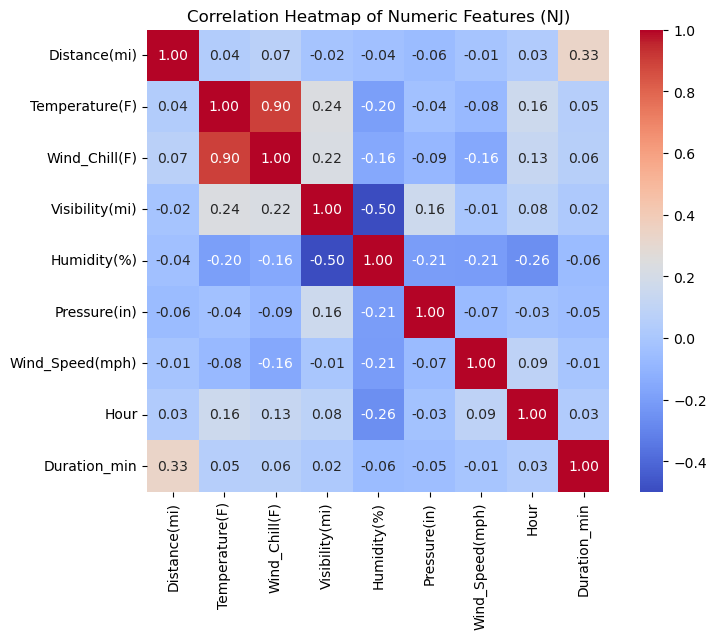

In [37]:
import seaborn as sns
corr_matrix = df_clean[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('Correlation Heatmap of Numeric Features (NJ)')
plt.show()

In [ ]:
df_clean[df_clean["Severity"]==""]

In [44]:
df_clean[df_clean["Severity_Class"]=="Major"]

,ID,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),Description,Street,City,County,State,Timezone,Weather_Timestamp,Temperature(F),Wind_Chill(F),Visibility(mi),Pressure(in),Humidity(%),Weather_Condition,Wind_Direction,Wind_Speed(mph),Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Hour,Weekday,Month,Day,Day_of_week,Is_weekend,Duration_min,Weather_raw,Weather_Short,Season,Severity_Class,Wind_Direction_clean,Street_encoded,City_encoded
0,A-194257,3,2016-11-30 16:25:41,2016-11-30 17:10:30,41.139324,-74.169876,0.0100,Right lane blocked due to accident on I-87 Sou...,Route 17,Sloatsburg,Rockland,NY,US/Eastern,2016-11-30 16:53:00,53.1,51.0,1.0,29.810,93.0,Overcast,East,11.5,0,0,0,0,0,0,0,0,0,0,0,0,0,16,Wednesday,November,30,2,0,44.816667,overcast,Cloudy/Clear,Autumn,Major,E,118,648
1,A-194258,3,2016-11-30 15:40:06,2016-11-30 17:09:40,41.118748,-74.159744,1.4925,Accident on I-87 Southbound between Exit 14B C...,I-287 S,Suffern,Rockland,NY,US/Eastern,2016-11-30 15:53:00,53.1,51.0,1.0,29.830,93.0,Overcast,ENE,8.1,0,0,0,0,0,0,0,0,0,0,0,0,0,15,Wednesday,November,30,2,0,89.566667,overcast,Cloudy/Clear,Autumn,Major,ENE,141,896
2,A-194259,3,2016-11-30 15:26:18,2016-11-30 16:56:02,41.014034,-73.717239,1.1700,Accident on I-287 Cross Westchester Expy Eastb...,Hutchinson River Pkwy S,White Plains,Westchester,NY,US/Eastern,2016-11-30 15:56:00,52.0,51.0,2.0,29.810,93.0,Light Rain,East,17.3,0,0,0,0,1,0,0,0,0,0,0,0,0,15,Wednesday,November,30,2,0,89.733333,light rain,Rain/Precip,Autumn,Major,E,1682,2468
3,A-194260,3,2016-11-30 16:14:11,2016-11-30 16:59:00,41.390369,-73.597969,0.0100,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,US/Eastern,2016-11-30 15:53:00,52.0,51.0,3.0,29.860,89.0,Rain,East,10.4,0,0,0,0,0,0,0,0,0,0,0,0,0,16,Wednesday,November,30,2,0,44.816667,rain,Rain/Precip,Autumn,Major,E,1895,2658
4,A-194261,3,2016-11-30 16:17:57,2016-11-30 17:02:44,41.390369,-73.597969,0.0100,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,US/Eastern,2016-11-30 15:53:00,52.0,51.0,3.0,29.860,89.0,Rain,East,10.4,0,0,0,0,0,0,0,0,0,0,0,0,0,16,Wednesday,November,30,2,0,44.783333,rain,Rain/Precip,Autumn,Major,E,1895,2658
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347944,A-7777350,3,2019-08-23 19:22:58,2019-08-23 19:51:43,43.094250,-77.803120,0.4050,At RT-259/Exit 4 - Overturned heavy truck. 2 l...,I-490 E,Churchville,Monroe,NY,US/Eastern,2019-08-23 18:54:00,70.0,70.0,10.0,29.510,44.0,Fair,N,10.0,0,0,0,0,1,0,0,0,0,0,0,0,0,19,Friday,August,23,4,0,28.750000,fair,Cloudy/Clear,Summer,Major,N,1392,359
347946,A-7777354,4,2019-08-23 18:00:29,2019-08-23 18:29:30,42.486300,-75.117740,0.0360,Closed at CR-11 (West) - Road closed due to ac...,State Highway 23,Oneonta,Otsego,NY,US/Eastern,2019-08-23 17:53:00,67.0,67.0,10.0,28.905,52.0,Mostly Cloudy,N,13.0,0,0,0,0,0,0,0,0,0,0,0,0,0,18,Friday,August,23,4,0,29.016667,mostly cloudy,Cloudy/Clear,Summer,Major,N,14,46
347947,A-7777355,4,2019-08-23 18:00:29,2019-08-23 18:29:30,42.486681,-75.118217,0.0360,Closed at CR-11 (West) - Road closed due to ac...,State Highway 23,Oneonta,Otsego,NY,US/Eastern,2019-08-23 17:53:00,67.0,67.0,10.0,28.905,52.0,Mostly Cloudy,N,13.0,0,0,0,0,0,0,0,0,0,0,0,0,0,18,Friday,August,23,4,0,29.016667,mostly cloudy,Cloudy/Clear,Summer,Major,N,14,46
347948,A-7777360,3,2019-08-23 22:00:19,2019-08-23 22:29:12,43.056409,-76.542434,1.3580,At Lippoldt Rd - Accident. Lane blocked.,State Route 31,Weedsport,Cayuga,NY,US/Eastern,2019-08-23 21:54:00,65.0,65.0,10.0,29.620,63.0,Cloudy,NE,8.0,0,0,0,0,0,0,0,0,0,0,0,0,0,22,Friday,August,23,4,0,28.883333,cloudy,Cloudy/Clear,Summer,Major,NE,78,350


In [38]:
#Drop Wind_Chill(F) because it is highly collinear with Temperature(F) and adds redundant information


In [39]:
df_clean["Wind_Direction"].unique()

array(['East', 'ENE', 'South', 'SSE', 'NE', 'NNE', 'North', 'West', 'NW',
       'WNW', 'Variable', 'SW', 'WSW', 'ESE', 'NNW', 'Calm', 'SE', 'SSW',
       'N', 'VAR', 'CALM', 'E', 'S', 'W', 'Missing'], dtype=object)

## Summary
- The notebook handled missing values, engineered datetime features, capped outliers, and performed one-hot encoding.
- Did Feature Engineering and Feature selection
- Cleaned data to disk with `df_final.to_csv('data/clean/US_Accidents_March23_NY_Clean.csv', index=False)`.

In [40]:
df_clean[df_clean["Wind_Direction"]=="Variable"]

,ID,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),Description,Street,City,County,State,Timezone,Weather_Timestamp,Temperature(F),Wind_Chill(F),Visibility(mi),Pressure(in),Humidity(%),Weather_Condition,Wind_Direction,Wind_Speed(mph),Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Hour,Weekday,Month,Day,Day_of_week,Is_weekend,Duration_min,Weather_raw,Weather_Short,Season,Severity_Class,Wind_Direction_clean,Street_encoded,City_encoded
42,A-194358,3,2016-12-01 07:25:24,2016-12-01 07:54:56,40.633396,-74.015869,0.010,Left lane blocked due to accident on I-278 Gow...,Gowanus Expy E,Brooklyn,Kings,NY,US/Eastern,2016-12-01 07:15:00,53.6,51.0,10.0,30.41,82.0,Overcast,Variable,4.6,0,0,0,0,0,0,0,0,0,0,0,0,0,7,Thursday,December,1,3,0,29.533333,overcast,Cloudy/Clear,Winter,Major,Variable,338,17958
51,A-194377,3,2016-12-01 07:45:09,2016-12-01 08:29:56,42.732628,-73.698120,0.010,Right hand shoulder closed due to accident on ...,I-787 N,Watervliet,Albany,NY,US/Eastern,2016-12-01 07:49:00,48.2,51.0,10.0,29.55,87.0,Overcast,Variable,4.6,0,0,0,0,0,0,0,0,0,0,0,0,0,7,Thursday,December,1,3,0,44.783333,overcast,Cloudy/Clear,Winter,Major,Variable,1077,1236
54,A-194388,3,2016-12-01 07:49:40,2016-12-01 08:34:25,42.649979,-73.713722,0.010,Right hand shoulder closed due to accident on ...,I-90 E,Rensselaer,Rensselaer,NY,US/Eastern,2016-12-01 07:49:00,48.2,51.0,10.0,29.55,87.0,Overcast,Variable,4.6,0,0,0,0,0,0,0,0,0,0,0,0,0,7,Thursday,December,1,3,0,44.750000,overcast,Cloudy/Clear,Winter,Major,Variable,7568,613
148,A-194558,2,2016-12-02 07:09:04,2016-12-02 07:38:36,40.782818,-73.943871,0.010,Center lane blocked due to accident on FDR Dr ...,E 96th St,New York,New York,NY,US/Eastern,2016-12-02 06:51:00,41.0,38.0,10.0,29.90,60.0,Clear,Variable,4.6,0,0,1,0,0,0,0,0,0,0,0,1,0,7,Friday,December,2,4,0,29.533333,clear,Cloudy/Clear,Winter,Moderate,Variable,420,18628
181,A-194628,2,2016-12-02 12:27:57,2016-12-02 12:57:25,40.801270,-73.929916,0.010,Left lane blocked due to accident on Harlem Ri...,Robert F Kennedy Bridge,New York,New York,NY,US/Eastern,2016-12-02 12:51:00,50.0,51.0,10.0,29.86,43.0,Mostly Cloudy,Variable,6.9,0,0,0,0,0,0,0,0,0,0,0,0,0,12,Friday,December,2,4,0,29.466667,mostly cloudy,Cloudy/Clear,Winter,Moderate,Variable,237,18628
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
344331,A-7700564,2,2017-08-25 16:53:56,2017-08-25 22:53:56,40.850020,-73.943990,0.899,Between Amsterdam Ave/Harlem River Dr and Huds...,George Washington Brg,New York,New York,NY,US/Eastern,2017-08-25 16:51:00,73.9,51.0,10.0,30.11,52.0,Overcast,Variable,4.6,0,0,0,0,1,0,0,0,0,0,0,0,0,16,Friday,August,25,4,0,274.266667,overcast,Cloudy/Clear,Summer,Moderate,Variable,1592,18628
344332,A-7700566,2,2017-08-25 17:22:26,2017-08-25 23:22:26,41.736220,-73.776830,0.000,At Drake Rd - Accident.,Rossway Rd,Pleasant Valley,Dutchess,NY,US/Eastern,2017-08-25 16:53:00,75.0,51.0,10.0,30.09,43.0,Partly Cloudy,Variable,4.6,0,0,0,0,0,0,0,0,0,1,0,0,0,17,Friday,August,25,4,0,274.266667,partly cloudy,Cloudy/Clear,Summer,Moderate,Variable,4,378
344408,A-7702228,2,2017-08-30 07:21:51,2017-08-30 13:21:51,40.736300,-73.927060,0.426,Between I-278 and Van Dam St - Accident.,Long Island Expy W,Long Island City,Queens,NY,US/Eastern,2017-08-30 07:51:00,61.0,51.0,10.0,29.98,83.0,Partly Cloudy,Variable,6.9,0,0,0,0,0,0,0,0,0,0,0,0,0,7,Wednesday,August,30,2,0,274.266667,partly cloudy,Cloudy/Clear,Summer,Moderate,Variable,6635,1096
344411,A-7702239,3,2017-08-30 08:56:21,2017-08-30 14:56:21,40.814762,-73.934390,0.399,At Park Ave/NB Exit 21/SB Exit 20 - Accident.,Harlem River Dr S,New York,New York,NY,US/Eastern,2017-08-30 08:51:00,64.0,51.0,10.0,29.98,73.0,Clear,Variable,4.6,0,0,0,0,0,0,0,0,0,0,0,0,0,8,Wednesday,August,30,2,0,274.266667,clear,Cloudy/Clear,Summer,Major,Variable,52